# 11 — Robustesse des stratégies : quelle stratégie suivre ?

Preuves pour décider, **sans changer la stratégie suivie** : grille Momentum en walk-forward, stratégies simples alternatives, intervalles de confiance par bootstrap et stabilité des paramètres. Même moteur que `python main.py research`. Aucun ordre n'est exécuté.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'config').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_prices
from src.features import to_monthly_prices
from src.monthly_pipeline import load_config, run_monthly_pipeline
from src.research import STRATEGY_LABELS, conclusion_lines, run_research
from src.universe import asset_roles, load_universe

prices = load_prices(PROJECT_ROOT / 'data' / 'processed' / 'universe_prices.csv')
config = load_config(PROJECT_ROOT / 'config' / 'strategy_params.yaml')
roles = asset_roles(load_universe(PROJECT_ROOT / 'config' / 'assets.yaml'))
monthly = run_monthly_pipeline(prices, config, asset_roles=roles).monthly_prices
cash_return = to_monthly_prices(prices['CSH2.PA']).reindex(monthly.index).pct_change(fill_method=None).fillna(0.0)
study = run_research(monthly, config, roles=roles, cash_return=cash_return)
print(f"Fenêtre commune : {study['start']} → {study['end']} ({study['n_months']} mois)")

Fenêtre commune : 2019-01-31 → 2026-08-31 (92 mois)


## Tableau de preuves

In [2]:
rows = []
for name, item in study['results'].items():
    s, vs = item['stats'], item['vs_benchmark']
    rows.append({'stratégie': STRATEGY_LABELS[name].format(benchmark='CW8.PA', bond='OBLI.PA'),
                 'CAGR': s['cagr'], 'volatilité': s['volatility'], 'Sharpe': s['sharpe'],
                 'écart Sharpe': None if vs is None else vs['diff'],
                 'IC bas': None if vs is None else vs['low'], 'IC haut': None if vs is None else vs['high'],
                 'max DD': s['max_drawdown']})
table = pd.DataFrame(rows).set_index('stratégie').sort_values('Sharpe', ascending=False)
table.style.format({'CAGR': '{:.1%}', 'volatilité': '{:.1%}', 'Sharpe': '{:.2f}', 'écart Sharpe': '{:+.2f}',
                    'IC bas': '{:+.2f}', 'IC haut': '{:+.2f}', 'max DD': '{:.1%}'}, na_rep='—')

,CAGR,volatilité,Sharpe,écart Sharpe,IC bas,IC haut,max DD
stratégie,,,,,,,
Inverse volatilité (actions),16.0%,13.5%,1.17,+0.10,-0.15,+0.31,-16.5%
Buy & Hold CW8.PA,14.7%,13.8%,1.07,—,—,—,-18.6%
80/20 CW8.PA / OBLI.PA,11.7%,11.5%,1.02,-0.04,-0.11,+0.04,-15.6%
Dual momentum (actions / obligataire / cash),17.5%,18.1%,0.98,-0.08,-0.60,+0.36,-20.1%
Top 3 équipondéré + tendance,12.9%,13.7%,0.96,-0.11,-0.52,+0.22,-16.6%
60/40 CW8.PA / OBLI.PA,8.7%,9.3%,0.94,-0.13,-0.29,+0.07,-15.5%
Momentum 12-1 MA10 top 1 (défaut),13.8%,17.1%,0.84,-0.23,-0.67,+0.15,-24.3%
Momentum + Volatility Targeting,8.8%,12.7%,0.73,-0.34,-0.85,+0.09,-20.9%
"Momentum, paramètres choisis en walk-forward",6.8%,12.9%,0.57,-0.50,-0.90,-0.12,-27.5%


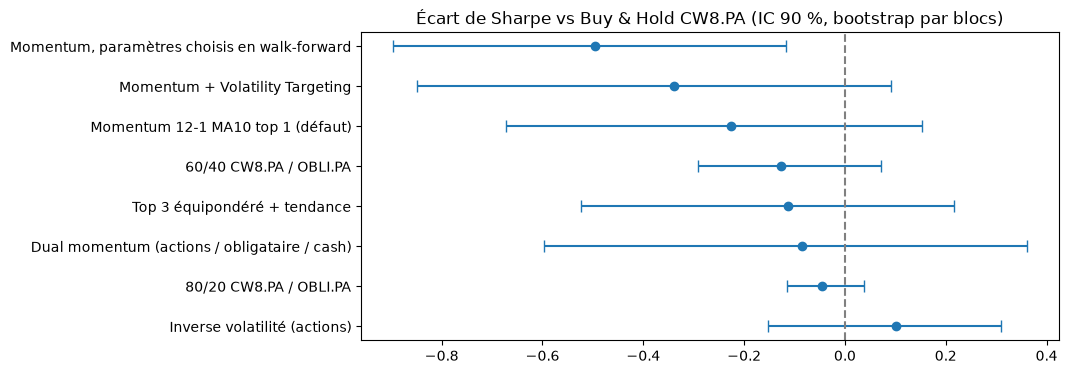

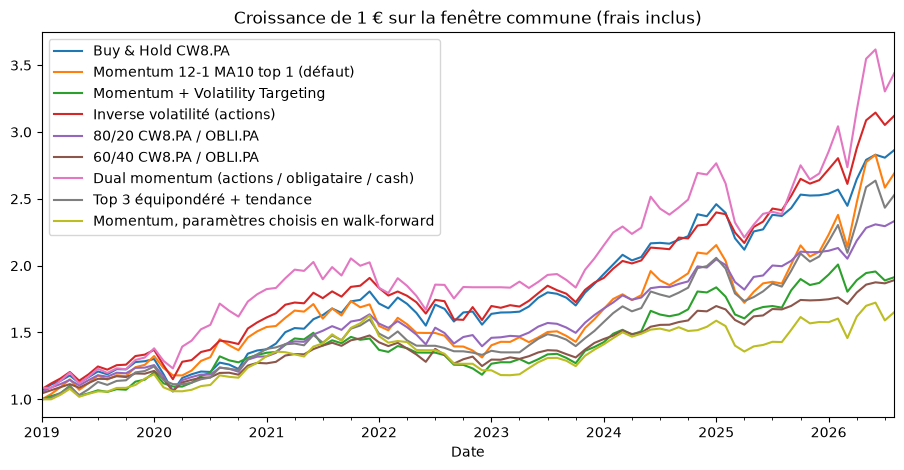

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
ci = table.dropna(subset=['écart Sharpe'])
ax.errorbar(ci['écart Sharpe'], range(len(ci)), xerr=[ci['écart Sharpe'] - ci['IC bas'], ci['IC haut'] - ci['écart Sharpe']],
            fmt='o', capsize=4)
ax.axvline(0, color='grey', linestyle='--')
ax.set_yticks(range(len(ci)), ci.index)
ax.set_title('Écart de Sharpe vs Buy & Hold CW8.PA (IC 90 %, bootstrap par blocs)')
plt.show()

equity = pd.DataFrame({STRATEGY_LABELS[k].format(benchmark='CW8.PA', bond='OBLI.PA'): (1 + v['returns']).cumprod()
                       for k, v in study['results'].items()})
equity.plot(figsize=(11, 5), title='Croissance de 1 € sur la fenêtre commune (frais inclus)')
plt.show()

## Walk-forward et stabilité de la grille

In [4]:
display(pd.DataFrame(study['walk_forward']['choices']))
stability = study['stability']
print(f"Corrélation de rang des Sharpe entre les deux moitiés : {stability['rank_correlation']:.2f}")
display(stability['table'].head(10).style.format('{:.2f}'))

,test_start,test_end,config,train_sharpe,train_months
0,2019-01-31,2019-12-31,L3-MA6-top3-VT,0.739653,38
1,2020-01-31,2020-12-31,L12-MA6-top3-noVT,1.303362,47
2,2021-01-31,2021-12-31,L3-MA12-top1-noVT,1.254472,59
3,2022-01-31,2022-12-31,L3-MA12-top1-noVT,1.397041,71
4,2023-01-31,2023-12-31,L3-MA12-top3-noVT,0.944682,83
5,2024-01-31,2024-12-31,L3-MA12-top3-noVT,0.983896,95
6,2025-01-31,2025-12-31,L6-MA12-top3-noVT,1.054357,107
7,2026-01-31,2026-08-31,L3-MA12-top3-noVT,0.973810,119


Corrélation de rang des Sharpe entre les deux moitiés : -0.18


,sharpe_total,sharpe_1re_moitie,sharpe_2e_moitie
L12-MA12-top3-noVT,1.02,0.89,1.12
L6-MA12-top3-noVT,1.01,1.16,0.89
L12-MA12-top2-noVT,1.00,0.80,1.16
L9-MA12-top3-noVT,0.97,0.93,1.00
L6-MA12-top2-noVT,0.97,1.05,0.91
L3-MA12-top3-noVT,0.97,1.21,0.74
L12-MA10-top2-noVT,0.96,0.64,1.22
L12-MA10-top3-noVT,0.96,0.74,1.14
L6-MA12-top1-noVT,0.90,1.04,0.76
L12-MA10-top2-VT,0.89,0.64,1.11


In [5]:
for line in conclusion_lines(study):
    print(line)

- Aucune stratégie ne bat le Buy & Hold CW8.PA en Sharpe de façon statistiquement robuste sur cette période (tous les intervalles à 90 % contiennent zéro ou sont négatifs).
- Sharpe significativement inférieur au Buy & Hold : Momentum, paramètres choisis en walk-forward.
- Stabilité de la grille Momentum : corrélation de rang -0.18 entre les deux moitiés de la période (classement instable : les « meilleurs » paramètres d'hier ne le restent pas).
- 80 variantes testées : le meilleur résultat observé est probablement surestimé (tests multiples) ; ne retenir que des écarts robustes et explicables.
- Le choix de la stratégie à suivre reste une décision humaine (`paper-decision`).


## Limites

- Fenêtre commune courte (depuis 2019) et univers restreint ; un seul grand krach (2020).
- 80 variantes testées : le meilleur résultat observé est probablement surestimé.
- Le choix de la stratégie suivie reste une décision humaine.